# Fase 2 — Modelos de Machine Learning (previsão de hits)

**Roteiro**
0. Setup e configuração
1. Carga dos dados e definição do alvo
2. Treino / validação / teste (usando spotify_train.csv e spotify_test.csv como estão)
3. Por que o Random Forest "chutava"? (diagnóstico)
4. Funções de avaliação (métricas certas para classe rara + limiar escolhido na validação)
5. Modelos: Baseline, Random Forest, XGBoost, LightGBM, TensorFlow (MLP)
6. Comparação final, curvas e importância de variáveis

**Regras deste notebook**
- O limiar de decisão é escolhido na **validação**, nunca no teste.
- O teste é usado **uma vez**, no fim, para reportar.
- Métrica principal: **PR-AUC (Average Precision)** e **ROC-AUC**; acurácia é só informativa (com ~5% de hits, "chutar sempre não-hit" já dá ~95%).
- Nenhuma coluna derivada do alvo entra nas features (`hit_probability`, `hit_rate`, `streams_*`, `chart_*`, `stream_density`, `artist_stream_*`...).

In [1]:
!pip install pandas numpy scikit-learn xgboost lightgbm tensorflow matplotlib seaborn #instala as bibliotecas necessárias

import os, gc, warnings #gc libera espaço de memória
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, confusion_matrix, f1_score, precision_score,
                             recall_score, accuracy_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)

SEED = 42
np.random.seed(SEED)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 383.7 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.2/572.2 MB 185.4 kB/s eta 0:00:0000:0101:06
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.7/501.7 kB 190.9 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 211.4 kB/s eta 0:00:0000:0100:04
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 255.8 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 421.8 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 250.5 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 216.9 kB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 173.8 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 178.8 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 kB 223.3 kB/s eta 0:00:00a 0:00:01
     ━━

In [26]:
# ----------------- CONFIGURAÇÃO -----------------
HIT_LIMIAR_POP = 50          # apenas uma variavel para delimitar  track_popularity > 50 é hit
USE_CONTEXT    = True        # True: áudio + contexto (ano, gênero). False: só características de áudio
SAMPLE_FRAC    = None        # teste completo
VAL_SIZE = 0.15            # 15% do modelo de treinamento será usado para validação

# detecta onde estão os dados (Docker: /app/data/raw ; local: ../data/raw ou data/raw)
for base in ["/app/data/raw", "../data/raw", "data/raw"]:
    if os.path.exists(os.path.join(base, "spotify_train.csv")):
        DATA_DIR = base; break
else:
    raise FileNotFoundError("Não achei spotify_train.csv — ajuste DATA_DIR.")
print("DATA_DIR =", DATA_DIR)

AUDIO_NUM = ["energy", "valence", "danceability", "acousticness", "instrumentalness",
             "speechiness", "liveness", "loudness", "tempo", "duration_ms", "time_signature"] #key é tonalidade da música, mode é o tom se é alto ou baixo
AUDIO_CAT = ["key", "mode"]                  # tonalidade e modo (tratados como categoria)
CTX_NUM   = ["release_year"]                 # conhecido no lançamento -> não é vazamento
CTX_CAT   = ["genre_l1"]

NUM_COLS = AUDIO_NUM + (CTX_NUM if USE_CONTEXT else []) #se eu decidir usar o contexto, adiciona o ano
CAT_COLS = AUDIO_CAT + (CTX_CAT if USE_CONTEXT else []) #se eu decidir usar o contexto, usar genero

DATA_DIR = /app/data/raw


## 1. Carga dos dados e definição do alvo

In [27]:
usecols = (["track_artist", "track_popularity", "explicit_flag"] + AUDIO_NUM + AUDIO_CAT
           + CTX_NUM + CTX_CAT)
usecols = list(dict.fromkeys(usecols))
 #caso a lista dê duas variaveis iguais, deleta uma 
# Os arquivos são usados COMO ESTÃO: spotify_train.csv = treino(+validação), spotify_test.csv = teste.
# Eles só são empilhados numa tabela para facilitar o pré-processamento; a coluna _origem lembra de onde veio cada linha.
parts = []
for f, origem in [("spotify_train.csv", "train"), ("spotify_test.csv", "test")]:
    p_ = pd.read_csv(os.path.join(DATA_DIR, f), usecols=usecols)
    p_["_origem"] = origem
    parts.append(p_)
df = pd.concat(parts, ignore_index=True)
del parts; gc.collect()

if SAMPLE_FRAC:
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED).reset_index(drop=True)

df["is_hit"] = (df["track_popularity"] >= HIT_LIMIAR_POP).astype(int)
df["track_artist"] = df["track_artist"].fillna("desconhecido")
df["explicit_flag"] = df["explicit_flag"].astype(int)
df["time_signature"] = df["time_signature"].fillna(df["time_signature"].mode()[0])

print(df.shape)
print(df["is_hit"].value_counts(normalize=True).rename("proporção").to_frame())

(1064119, 20)
        proporção
is_hit           
0          0.9491
1          0.0509


## 2. Treino / Validação / Teste

- **Teste** = `spotify_test.csv`, do jeito que está.
- **Treino + Validação** = `spotify_train.csv`; uma parte (15%) vira validação, agrupada por artista (nenhum artista fica nos dois). A validação serve para escolher o limiar e parar o early stopping.

> Atenção: os arquivos originais compartilham muitos artistas entre treino e teste, então a nota no teste tende a ser um pouco otimista.

In [28]:
y  = df["is_hit"].values
grp = df["track_artist"].values

# TESTE = exatamente o spotify_test.csv. TREINO/VALIDAÇÃO = spotify_train.csv dividido (agrupado por artista).
idx_test  = np.where(df["_origem"].values == "test")[0]
idx_trval = np.where(df["_origem"].values == "train")[0]

gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)
i_tr, i_va = next(gss2.split(df.iloc[idx_trval], y[idx_trval], grp[idx_trval]))
idx_train, idx_val = idx_trval[i_tr], idx_trval[i_va]

for nome, ix in [("treino", idx_train), ("validação", idx_val), ("teste", idx_test)]:
    print(f"{nome:10s} n={len(ix):>8,}  % hits={y[ix].mean()*100:5.2f}%  artistas={len(set(grp[ix])):,}")

print(f"Artistas em comum treino x teste (herdado dos arquivos originais): {len(set(grp[idx_train]) & set(grp[idx_test])):,}")
assert not (set(grp[idx_train]) & set(grp[idx_val])),  "artista repetido entre treino e validação!"

treino     n= 802,434  % hits= 5.11%  artistas=55,685
validação  n= 143,449  % hits= 4.99%  artistas=9,827
teste      n= 118,236  % hits= 5.02%  artistas=33,570
Artistas em comum treino x teste (herdado dos arquivos originais): 26,784


In [29]:
# ---- Matrizes de features
# (a) versão 'crua' com categorias nativas -> LightGBM
Xraw = df[NUM_COLS + ["explicit_flag"] + CAT_COLS].copy()
for c in CAT_COLS:
    Xraw[c] = Xraw[c].astype("category")

# (b) versão numérica (one-hot) -> RF, XGBoost, regressão logística, rede neural
Xnum = pd.get_dummies(Xraw, columns=CAT_COLS, dtype="float32")
Xnum = Xnum.astype("float32")

# (c) versão escalada p/ modelos sensíveis à escala (LR e rede neural)
SKEWED = [c for c in ["speechiness", "instrumentalness", "duration_ms", "acousticness", "liveness"] if c in Xnum]
Xs = Xnum.copy()
for c in SKEWED:
    Xs[c] = np.log1p(Xs[c].clip(lower=0))
scaler = StandardScaler().fit(Xs.iloc[idx_train])
Xs = pd.DataFrame(scaler.transform(Xs), columns=Xs.columns, index=Xs.index).astype("float32")

y_tr, y_va, y_te = y[idx_train], y[idx_val], y[idx_test]
print("Nº de features:", Xnum.shape[1])
print(list(Xnum.columns))

Nº de features: 45
['energy', 'valence', 'danceability', 'acousticness', 'instrumentalness', 'speechiness', 'liveness', 'loudness', 'tempo', 'duration_ms', 'time_signature', 'release_year', 'explicit_flag', 'key_0', 'key_1', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8', 'key_9', 'key_10', 'key_11', 'mode_0', 'mode_1', 'genre_l1_Blues', 'genre_l1_Classical', 'genre_l1_Country', 'genre_l1_Electronic', 'genre_l1_Folk', 'genre_l1_Gospel', 'genre_l1_Hip-Hop', 'genre_l1_Instrumental', 'genre_l1_Jazz', 'genre_l1_Latin', 'genre_l1_Metal', 'genre_l1_Pop', 'genre_l1_R&B', 'genre_l1_Reggae', 'genre_l1_Rock', 'genre_l1_Soundtrack', 'genre_l1_Unknown', 'genre_l1_World']


Baseline 'sempre não-hit': acurácia = 95.01%
AUC treino = 1.000  |  AUC validação = 0.858   <- overfitting
Valores distintos de probabilidade na validação: 476 (de 0.00 a 1.00 em passos de 0.01)
% das músicas com prob < 0.10: 86.2%


,limiar,prev_hits,recall,precisao
0,0.5000,966,0.0922,0.6832
1,0.4000,1829,0.1523,0.5960
2,0.3000,3522,0.2363,0.4801
3,0.2500,5150,0.3052,0.4241
4,0.2000,7487,0.3831,0.3662
5,0.1000,19752,0.6408,0.2322
6,0.0500,41928,0.8170,0.1395


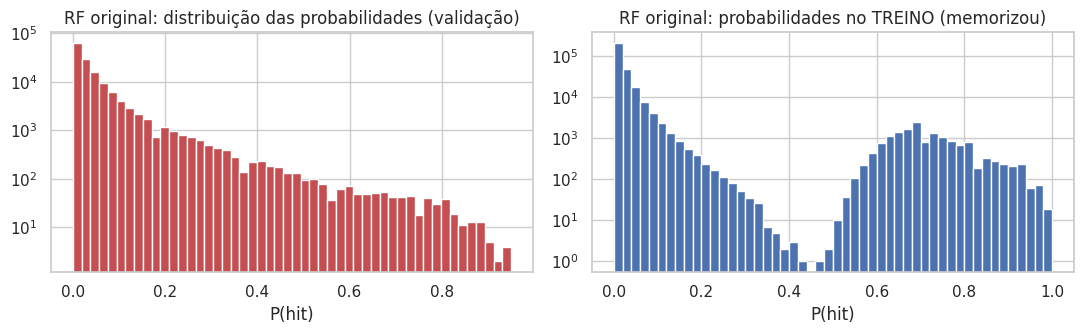

30210

In [30]:
# Reproduz o problema (amostra de 300 mil linhas do treino para ser rápido)
rng = np.random.RandomState(SEED)
sub = rng.choice(idx_train, size=min(300_000, len(idx_train)), replace=False)

rf_orig = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                 random_state=SEED, n_jobs=-1)       # == seu RF original
rf_orig.fit(Xnum.iloc[sub], y[sub])

p_tr_o = rf_orig.predict_proba(Xnum.iloc[sub])[:, 1]
p_va_o = rf_orig.predict_proba(Xnum.iloc[idx_val])[:, 1]

print(f"Baseline 'sempre não-hit': acurácia = {(1 - y_va.mean())*100:.2f}%")
print(f"AUC treino = {roc_auc_score(y[sub], p_tr_o):.3f}  |  AUC validação = {roc_auc_score(y_va, p_va_o):.3f}   <- overfitting")
print(f"Valores distintos de probabilidade na validação: {len(np.unique(p_va_o))} (de 0.00 a 1.00 em passos de 0.01)")
print(f"% das músicas com prob < 0.10: {(p_va_o < 0.10).mean()*100:.1f}%")

linhas = []
for t in [0.5, 0.4, 0.3, 0.25, 0.2, 0.1, 0.05]:
    pr = (p_va_o >= t).astype(int)
    linhas.append(dict(limiar=t, prev_hits=pr.sum(), recall=recall_score(y_va, pr),
                       precisao=precision_score(y_va, pr, zero_division=0)))
display(pd.DataFrame(linhas))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(p_va_o, bins=50, color="C3"); ax[0].set_yscale("log")
ax[0].set_title("RF original: distribuição das probabilidades (validação)")
ax[0].set_xlabel("P(hit)")
ax[1].hist(p_tr_o, bins=50, color="C0"); ax[1].set_yscale("log")
ax[1].set_title("RF original: probabilidades no TREINO (memorizou)")
ax[1].set_xlabel("P(hit)")
plt.tight_layout(); plt.show()
del rf_orig; gc.collect()

## 4. Funções de avaliação

- Limiar escolhido na **validação** maximizando F1 (você pode trocar por outro critério, ver `criterio`).
- Reporta: ROC-AUC, PR-AUC (a baseline de PR-AUC é a taxa de hits ≈ 5%), F1/precisão/recall dos hits no limiar escolhido, e **lift no top 5%** (quantas vezes mais hits existem entre as 5% músicas mais bem ranqueadas do que ao acaso).

In [31]:
RESULTADOS = {}   # nome -> dict com métricas e probabilidades

def melhor_limiar(y_true, p, criterio="f1", precisao_min=0.30):
    prec, rec, thr = precision_recall_curve(y_true, p)
    prec, rec = prec[:-1], rec[:-1]
    if criterio == "f1":
        score = 2 * prec * rec / (prec + rec + 1e-12)
    elif criterio == "recall_com_precisao_min":     # maximiza recall mantendo precisão >= precisao_min
        score = np.where(prec >= precisao_min, rec, -1)
    return float(thr[np.argmax(score)])

def lift_topk(y_true, p, k=0.05):
    n = int(len(p) * k)
    top = np.argsort(-p)[:n]
    return y_true[top].mean() / y_true.mean(), y_true[top].mean()

def avaliar(nome, p_val, p_test, criterio="f1", mostrar=True):
    t = melhor_limiar(y_va, p_val, criterio)
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    lift, prec_top = lift_topk(y_te, p_test)
    r = dict(modelo=nome, roc_auc=roc_auc_score(y_te, p_test),
             pr_auc=average_precision_score(y_te, p_test),
             limiar=t, precisao_hit=precision_score(y_te, pred, zero_division=0),
             recall_hit=recall_score(y_te, pred), f1_hit=f1_score(y_te, pred),
             acc_balanceada=balanced_accuracy_score(y_te, pred),
             acuracia=accuracy_score(y_te, pred), lift_top5=lift, prec_top5=prec_top,
             TN=tn, FP=fp, FN=fn, TP=tp)
    RESULTADOS[nome] = dict(metricas=r, p_test=p_test, p_val=p_val)
    if mostrar:
        print(f"\n=== {nome} ===  (limiar escolhido na validação = {t:.3f})")
        print(f"ROC-AUC {r['roc_auc']:.3f} | PR-AUC {r['pr_auc']:.3f} (baseline {y_te.mean():.3f}) | lift top5% {lift:.2f}x")
        print(f"Hits: precisão {r['precisao_hit']:.3f} | recall {r['recall_hit']:.3f} | F1 {r['f1_hit']:.3f} | acurácia {r['acuracia']:.3f}")
        print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")
    return r

def tabela_limiares(nome, limiares=(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7)):
    p = RESULTADOS[nome]["p_test"]
    rows = []
    for t in limiares:
        pr = (p >= t).astype(int)
        rows.append(dict(limiar=t, prev_hits=pr.sum(), precisao=precision_score(y_te, pr, zero_division=0),
                         recall=recall_score(y_te, pr), f1=f1_score(y_te, pr)))
    return pd.DataFrame(rows)

## 5. Modelos

### 5.0 Baseline — Regressão Logística
Modelo simples e interpretável; serve de piso: se os modelos complexos não o superarem, a complexidade não vale a pena.

In [32]:
lr = LogisticRegression(class_weight="balanced", max_iter=500, C=1.0, n_jobs=-1)
lr.fit(Xs.iloc[idx_train], y_tr)
avaliar("Regressão Logística",
        lr.predict_proba(Xs.iloc[idx_val])[:, 1],
        lr.predict_proba(Xs.iloc[idx_test])[:, 1])


=== Regressão Logística ===  (limiar escolhido na validação = 0.754)
ROC-AUC 0.814 | PR-AUC 0.279 (baseline 0.050) | lift top5% 6.18x
Hits: precisão 0.274 | recall 0.364 | F1 0.312 | acurácia 0.920
TN=106,573  FP=5,732  FN=3,772  TP=2,159


{'modelo': 'Regressão Logística',
 'roc_auc': 0.8141548304740225,
 'pr_auc': 0.27943820547988135,
 'limiar': 0.7542436252011044,
 'precisao_hit': 0.27360283867697377,
 'recall_hit': 0.36401955825324567,
 'f1_hit': 0.31240052090869624,
 'acc_balanceada': 0.6564899892686468,
 'acuracia': 0.9196183903379681,
 'lift_top5': 6.1751738633260675,
 'prec_top5': 0.30976146168161056,
 'TN': 106573,
 'FP': 5732,
 'FN': 3772,
 'TP': 2159}

### 5.1 Random Forest (corrigido)

O que mudou em relação ao original:
- `min_samples_leaf=30` e `max_depth=18`: folhas com dezenas de músicas → probabilidades **graduais** (0.03, 0.17, 0.41...), então o limiar passa a ter efeito de verdade.
- `class_weight='balanced_subsample'`: peso recalculado a cada amostra bootstrap.
- `max_features='sqrt'`, `max_samples=0.5`: mais diversidade entre árvores, menos overfitting e treino mais rápido.
- Limiar escolhido pela validação.

In [33]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=18, min_samples_leaf=30, max_features="sqrt",
    max_samples=0.5, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
rf.fit(Xnum.iloc[idx_train], y_tr)

p_va, p_te = rf.predict_proba(Xnum.iloc[idx_val])[:, 1], rf.predict_proba(Xnum.iloc[idx_test])[:, 1]
print("Valores distintos de probabilidade:", len(np.unique(p_te)))
avaliar("Random Forest", p_va, p_te)
display(tabela_limiares("Random Forest"))     # agora o limiar muda o resultado

Valores distintos de probabilidade: 118167

=== Random Forest ===  (limiar escolhido na validação = 0.691)
ROC-AUC 0.875 | PR-AUC 0.346 (baseline 0.050) | lift top5% 7.45x
Hits: precisão 0.302 | recall 0.498 | F1 0.376 | acurácia 0.917
TN=105,460  FP=6,845  FN=2,976  TP=2,955


,limiar,prev_hits,precisao,recall,f1
0,0.1000,90964,0.0648,0.9944,0.1217
1,0.2000,65792,0.0871,0.9659,0.1598
2,0.3000,47102,0.1150,0.9133,0.2043
3,0.4000,33242,0.1488,0.8341,0.2526
4,0.5000,22643,0.1922,0.7339,0.3047
5,0.6000,14690,0.2472,0.6124,0.3523
6,0.7000,9333,0.3071,0.4832,0.3755


In [34]:
# (opcional) busca de hiperparametros do RF numa amostra. Mude para True para rodar (demora).
RODAR_BUSCA = False

if RODAR_BUSCA:
    from sklearn.model_selection import RandomizedSearchCV
    amostra = np.random.RandomState(SEED).choice(idx_train, 200_000, replace=False)
    param_dist = {
        "n_estimators": [200, 300],
        "max_depth": [10, 14, 18, 24],
        "min_samples_leaf": [10, 30, 60, 100],
        "max_features": ["sqrt", 0.3, 0.5],
    }
    busca = RandomizedSearchCV(
        RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        param_dist, n_iter=10, scoring="average_precision", cv=3, random_state=SEED, verbose=1)
    busca.fit(Xnum.iloc[amostra], y[amostra])
    print(busca.best_params_, busca.best_score_)

### 5.2 XGBoost

Early stopping na validação (por PR-AUC) evita overfitting e escolhe o nº de árvores sozinho. `scale_pos_weight` usa a **raiz** da razão de classes (peso total deixa o modelo extremamente "otimista", como no seu XGBoost com 68% de acurácia e 35 mil falsos positivos); o limiar final é calibrado na validação de qualquer forma.

In [35]:
from xgboost import XGBClassifier

spw = np.sqrt((y_tr == 0).sum() / (y_tr == 1).sum())
xgb = XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=6, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=2.0, scale_pos_weight=spw,
    tree_method="hist", eval_metric="aucpr", early_stopping_rounds=50,
    random_state=SEED, n_jobs=-1)
xgb.fit(Xnum.iloc[idx_train], y_tr, eval_set=[(Xnum.iloc[idx_val], y_va)], verbose=100)
print("Melhor nº de árvores:", xgb.best_iteration)

avaliar("XGBoost", xgb.predict_proba(Xnum.iloc[idx_val])[:, 1], xgb.predict_proba(Xnum.iloc[idx_test])[:, 1])
display(tabela_limiares("XGBoost"))

[0]	validation_0-aucpr:0.26203
[100]	validation_0-aucpr:0.36502
[200]	validation_0-aucpr:0.37469
[300]	validation_0-aucpr:0.37993
[400]	validation_0-aucpr:0.38287
[500]	validation_0-aucpr:0.38448
[600]	validation_0-aucpr:0.38577
[686]	validation_0-aucpr:0.38620
Melhor nº de árvores: 636

=== XGBoost ===  (limiar escolhido na validação = 0.515)
ROC-AUC 0.886 | PR-AUC 0.397 (baseline 0.050) | lift top5% 8.17x
Hits: precisão 0.376 | recall 0.442 | F1 0.407 | acurácia 0.935
TN=107,954  FP=4,351  FN=3,308  TP=2,623


,limiar,prev_hits,precisao,recall,f1
0,0.1000,45308,0.1204,0.9196,0.2129
1,0.2000,27354,0.1742,0.8034,0.2863
2,0.3000,17375,0.2315,0.6783,0.3452
3,0.4000,11265,0.2953,0.5610,0.3870
4,0.5000,7448,0.3643,0.4574,0.4056
5,0.6000,4741,0.4510,0.3605,0.4007
6,0.7000,2737,0.5524,0.2549,0.3489


### 5.3 LightGBM (modelo extra)

Escolhido por ser, em dados tabulares grandes e desbalanceados, geralmente tão bom quanto o XGBoost e **bem mais rápido**, e porque trata **variáveis categóricas nativamente** (`key`, `mode`, `genre_l1`) sem one-hot — o que costuma ajudar quando o gênero importa. Como é um modelo de boosting como o XGBoost, também serve de checagem de robustez.

In [41]:
!apt-get update && apt-get install -y libgomp1

Hit:1 http://deb.debian.org/debian trixie InRelease
Get:2 http://deb.debian.org/debian trixie-updates InRelease [47.3 kB]
Get:3 http://deb.debian.org/debian-security trixie-security InRelease [43.4 kB]
Get:4 http://deb.debian.org/debian trixie/main amd64 Packages [9678 kB]
Get:5 http://deb.debian.org/debian trixie-updates/main amd64 Packages [1108 B]
Get:6 http://deb.debian.org/debian-security trixie-security/main amd64 Packages [306 kB]
Fetched 10.1 MB in 5s (2224 kB/s)                       
Reading package lists... Done
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  libgomp1
0 upgraded, 1 newly installed, 0 to remove and 6 not upgraded.
Need to get 137 kB of archives.
After this operation, 377 kB of additional disk space will be used.
Get:1 http://deb.debian.org/debian trixie/main amd64 libgomp1 amd64 14.2.0-19 [137 kB]
Fetched 137 kB in 0s (576 kB/s) 
debconf: unable to initialize fron

In [42]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

lgbm = LGBMClassifier(
    n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=100,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0,
    scale_pos_weight=spw, random_state=SEED, n_jobs=-1, verbose=-1)
lgbm.fit(Xraw.iloc[idx_train], y_tr,
         eval_set=[(Xraw.iloc[idx_val], y_va)], eval_metric="average_precision",
         callbacks=[early_stopping(50), log_evaluation(100)])
print("Melhor nº de árvores:", lgbm.best_iteration_)

avaliar("LightGBM", lgbm.predict_proba(Xraw.iloc[idx_val])[:, 1], lgbm.predict_proba(Xraw.iloc[idx_test])[:, 1])
display(tabela_limiares("LightGBM"))

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[9]	valid_0's average_precision: 0.341449	valid_0's binary_logloss: 0.172423
Melhor nº de árvores: 9

=== LightGBM ===  (limiar escolhido na validação = 0.207)
ROC-AUC 0.867 | PR-AUC 0.352 (baseline 0.050) | lift top5% 7.64x
Hits: precisão 0.339 | recall 0.443 | F1 0.384 | acurácia 0.929
TN=107,191  FP=5,114  FN=3,304  TP=2,627


,limiar,prev_hits,precisao,recall,f1
0,0.1000,32078,0.1500,0.8113,0.2532
1,0.2000,8596,0.3226,0.4675,0.3818
2,0.3000,2126,0.5447,0.1952,0.2875
3,0.4000,86,0.9070,0.0132,0.0259
4,0.5000,0,0.0000,0.0000,0.0000
5,0.6000,0,0.0000,0.0000,0.0000
6,0.7000,0,0.0000,0.0000,0.0000


### 5.4 TensorFlow / Keras (MLP)

Rede densa com BatchNorm + Dropout, entradas padronizadas (com `log1p` nas assimétricas), `class_weight` moderado, e early stopping pela **PR-AUC de validação**.

Epoch 1/40
392/392 - 14s - 36ms/step - loss: 0.4609 - pr_auc: 0.2252 - roc_auc: 0.8055 - val_loss: 0.2081 - val_pr_auc: 0.3313 - val_roc_auc: 0.8633 - learning_rate: 0.0010
Epoch 2/40
392/392 - 11s - 28ms/step - loss: 0.4096 - pr_auc: 0.3134 - roc_auc: 0.8475 - val_loss: 0.2109 - val_pr_auc: 0.3394 - val_roc_auc: 0.8676 - learning_rate: 0.0010
Epoch 3/40
392/392 - 11s - 28ms/step - loss: 0.3995 - pr_auc: 0.3260 - roc_auc: 0.8564 - val_loss: 0.2096 - val_pr_auc: 0.3453 - val_roc_auc: 0.8695 - learning_rate: 0.0010
Epoch 4/40
392/392 - 12s - 31ms/step - loss: 0.3945 - pr_auc: 0.3345 - roc_auc: 0.8606 - val_loss: 0.2090 - val_pr_auc: 0.3501 - val_roc_auc: 0.8714 - learning_rate: 0.0010
Epoch 5/40
392/392 - 11s - 27ms/step - loss: 0.3911 - pr_auc: 0.3402 - roc_auc: 0.8634 - val_loss: 0.2104 - val_pr_auc: 0.3528 - val_roc_auc: 0.8721 - learning_rate: 0.0010
Epoch 6/40
392/392 - 11s - 28ms/step - loss: 0.3889 - pr_auc: 0.3429 - roc_auc: 0.8653 - val_loss: 0.2089 - val_pr_auc: 0.3538 - val_ro

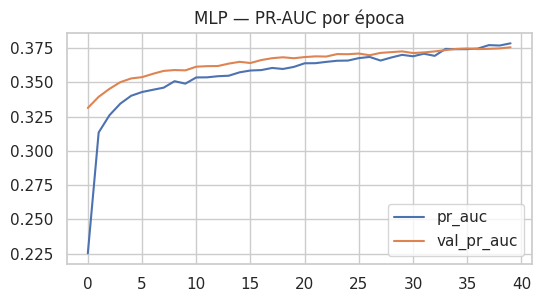

In [43]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)

Xtr_nn = Xs.iloc[idx_train].values.astype("float32")
Xva_nn = Xs.iloc[idx_val].values.astype("float32")
Xte_nn = Xs.iloc[idx_test].values.astype("float32")

def build_mlp(n_in):
    m = keras.Sequential([
        layers.Input(shape=(n_in,)),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(64,  activation="relu"), layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(name="pr_auc", curve="PR")])
    return m

mlp = build_mlp(Xtr_nn.shape[1])
cw = {0: 1.0, 1: float(spw)}          # peso moderado (raiz da razão), igual ao XGBoost/LightGBM
cbs = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
       keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=3, verbose=1)]

hist = mlp.fit(Xtr_nn, y_tr, validation_data=(Xva_nn, y_va), epochs=40, batch_size=2048,
               class_weight=cw, callbacks=cbs, verbose=2)

avaliar("TensorFlow MLP", mlp.predict(Xva_nn, batch_size=8192, verbose=0).ravel(),
                          mlp.predict(Xte_nn, batch_size=8192, verbose=0).ravel())

pd.DataFrame(hist.history)[["pr_auc", "val_pr_auc"]].plot(figsize=(6, 3), title="MLP — PR-AUC por época")
plt.show()

## 6. Comparação final

,roc_auc,pr_auc,lift_top5,limiar,precisao_hit,recall_hit,f1_hit,acc_balanceada,acuracia,TP,FP,FN,TN
modelo,,,,,,,,,,,,,
XGBoost,0.8864,0.3966,8.1684,0.5154,0.3761,0.4423,0.4065,0.7018,0.9352,2623,4351,3308,107954
TensorFlow MLP,0.8838,0.3843,8.0301,0.5104,0.3509,0.4709,0.4022,0.7125,0.9298,2793,5166,3138,107139
LightGBM,0.8668,0.3517,7.6389,0.2066,0.3394,0.4429,0.3843,0.6987,0.9288,2627,5114,3304,107191
Random Forest,0.8747,0.3456,7.4500,0.6908,0.3015,0.4982,0.3757,0.7186,0.9169,2955,6845,2976,105460
Regressão Logística,0.8142,0.2794,6.1752,0.7542,0.2736,0.3640,0.3124,0.6565,0.9196,2159,5732,3772,106573


Referência: PR-AUC de um modelo aleatório = taxa de hits = 0.050 | ROC-AUC aleatório = 0.5


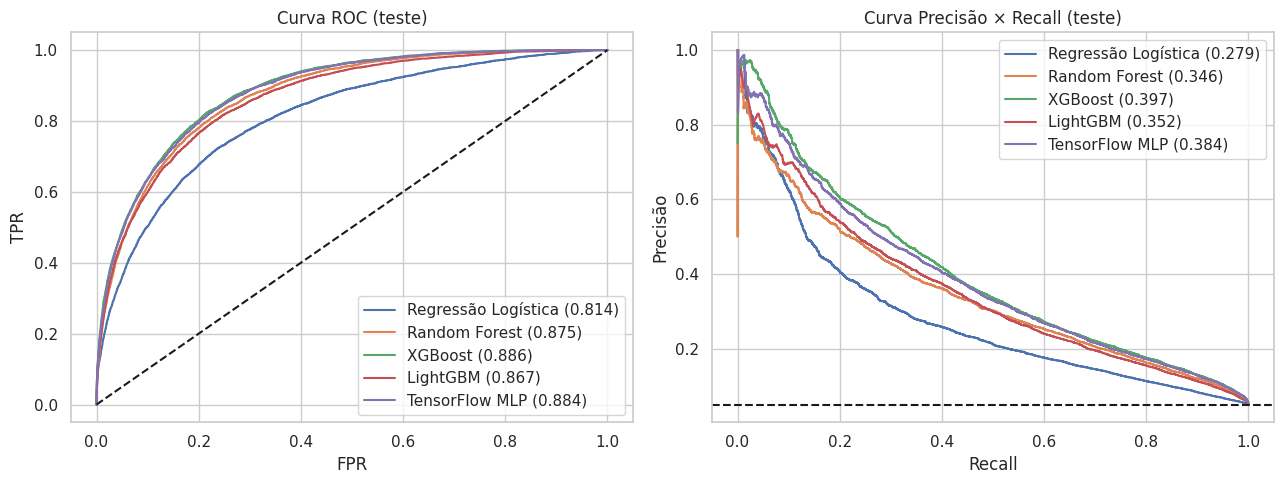

In [44]:
tab = pd.DataFrame([v["metricas"] for v in RESULTADOS.values()]).set_index("modelo")
display(tab[["roc_auc", "pr_auc", "lift_top5", "limiar", "precisao_hit", "recall_hit", "f1_hit",
             "acc_balanceada", "acuracia", "TP", "FP", "FN", "TN"]].sort_values("pr_auc", ascending=False))
print(f"Referência: PR-AUC de um modelo aleatório = taxa de hits = {y_te.mean():.3f} | ROC-AUC aleatório = 0.5")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nome, v in RESULTADOS.items():
    fpr, tpr, _ = roc_curve(y_te, v["p_test"])
    pr, rc, _ = precision_recall_curve(y_te, v["p_test"])
    ax[0].plot(fpr, tpr, label=f"{nome} ({v['metricas']['roc_auc']:.3f})")
    ax[1].plot(rc, pr, label=f"{nome} ({v['metricas']['pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="Curva ROC (teste)", xlabel="FPR", ylabel="TPR")
ax[1].axhline(y_te.mean(), color="k", ls="--"); ax[1].set(title="Curva Precisão × Recall (teste)", xlabel="Recall", ylabel="Precisão")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

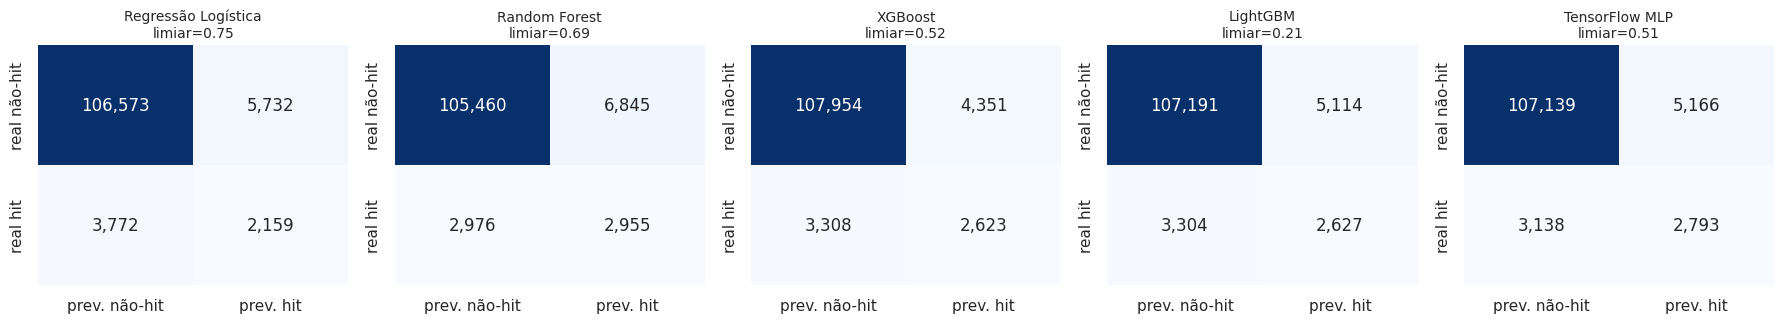

In [45]:
# Matrizes de confusão (no limiar escolhido na validação)
n = len(RESULTADOS)
fig, axs = plt.subplots(1, n, figsize=(3.6 * n, 3.4))
for a, (nome, v) in zip(np.atleast_1d(axs), RESULTADOS.items()):
    m = v["metricas"]
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["prev. não-hit", "prev. hit"], yticklabels=["real não-hit", "real hit"])
    a.set_title(f"{nome}\nlimiar={m['limiar']:.2f}", fontsize=10)
plt.tight_layout(); plt.show()

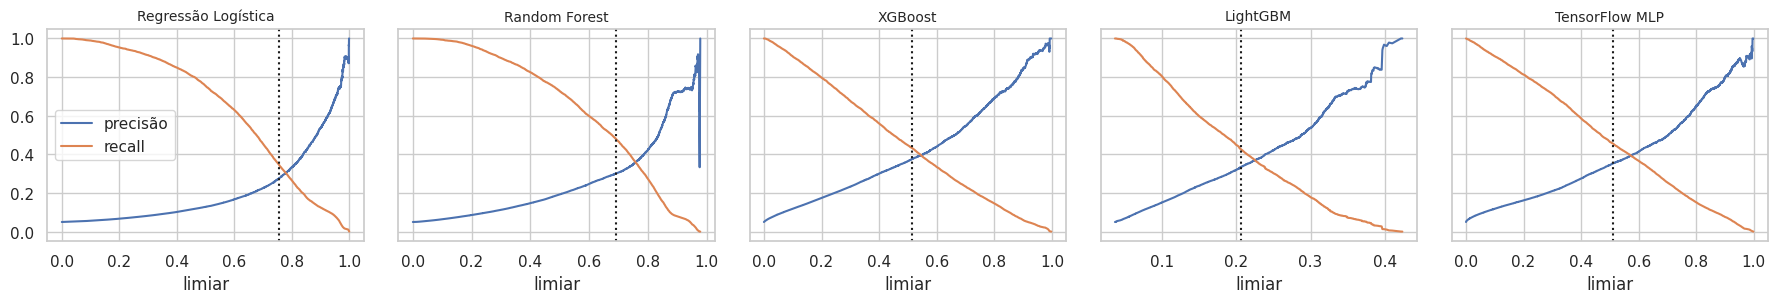

In [46]:
# Precisão e recall em função do limiar (validação) — para escolher o ponto de operação conforme o objetivo de negócio
fig, axs = plt.subplots(1, len(RESULTADOS), figsize=(3.6 * len(RESULTADOS), 3.2), sharey=True)
for a, (nome, v) in zip(np.atleast_1d(axs), RESULTADOS.items()):
    pr, rc, th = precision_recall_curve(y_va, v["p_val"])
    a.plot(th, pr[:-1], label="precisão"); a.plot(th, rc[:-1], label="recall")
    a.axvline(v["metricas"]["limiar"], color="k", ls=":"); a.set_title(nome, fontsize=10); a.set_xlabel("limiar")
np.atleast_1d(axs)[0].legend(); plt.tight_layout(); plt.show()

### Importância das variáveis

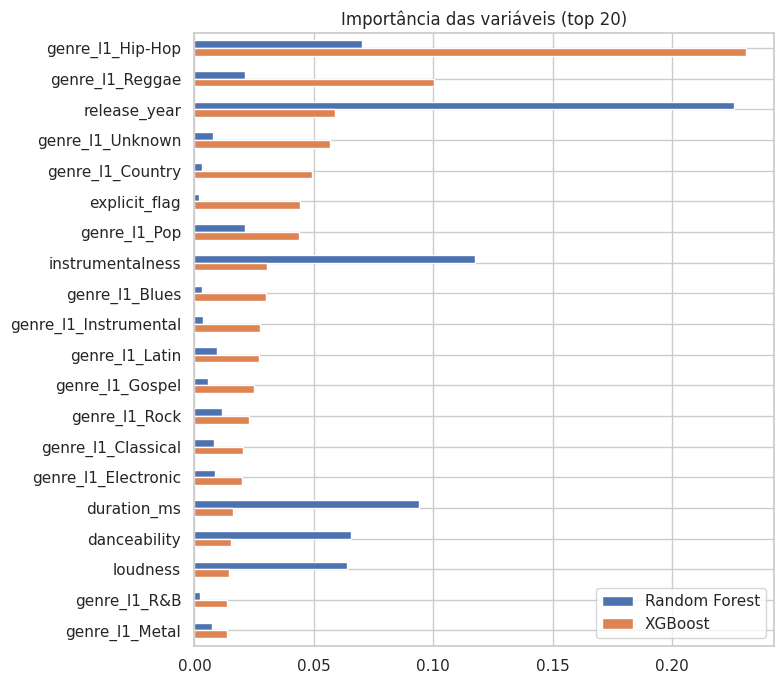

In [47]:
imp = pd.DataFrame({
    "Random Forest": pd.Series(rf.feature_importances_, index=Xnum.columns),
    "XGBoost": pd.Series(xgb.feature_importances_, index=Xnum.columns),
}).sort_values("XGBoost", ascending=False).head(20)
imp.plot(kind="barh", figsize=(8, 7), title="Importância das variáveis (top 20)").invert_yaxis()
plt.tight_layout(); plt.show()

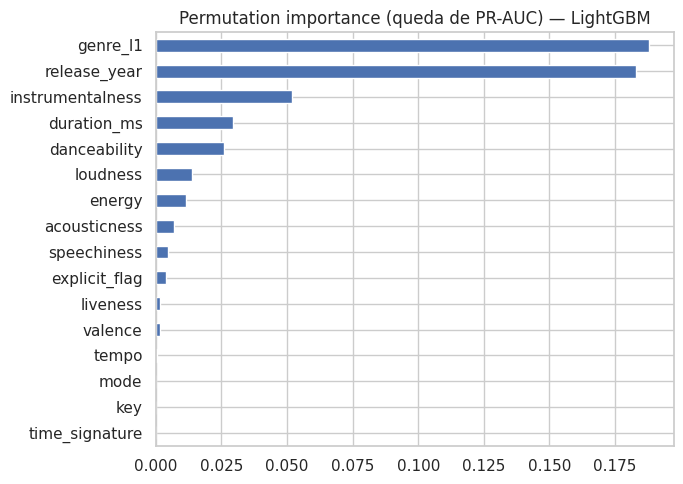

In [48]:
# Importância por permutação no teste (mais confiável que a importância interna) — LightGBM, amostra de 100 mil
from sklearn.inspection import permutation_importance
amostra_te = np.random.RandomState(SEED).choice(idx_test, min(100_000, len(idx_test)), replace=False)
pi = permutation_importance(lgbm, Xraw.iloc[amostra_te], y[amostra_te], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=1)
pd.Series(pi.importances_mean, index=Xraw.columns).sort_values().plot(
    kind="barh", figsize=(7, 5), title="Permutation importance (queda de PR-AUC) — LightGBM")
plt.tight_layout(); plt.show()

In [ ]:
# Salva a tabela de resultados e os modelos
import joblib
tab.to_csv("resultados_fase2.csv")
os.makedirs("modelos_salvos", exist_ok=True)
joblib.dump(rf, "modelos_salvos/rf_corrigido.joblib")
xgb.save_model("modelos_salvos/xgb.json")
lgbm.booster_.save_model("modelos_salvos/lgbm.txt")
mlp.save("modelos_salvos/mlp.keras")
print("Resultados e modelos salvos.")

## 7. Como interpretar e próximos passos

- Compare por **PR-AUC / ROC-AUC / lift**, que não dependem do limiar. Depois escolha o limiar conforme o objetivo:
  - achar o máximo de hits (aceita falsos positivos) → limiar baixo / `criterio="recall_com_precisao_min"`;
  - poucos alertas, mas confiáveis → limiar alto.
- Se os modelos ficarem com ROC-AUC ~0.70–0.75, isso é **o limite das variáveis de áudio**, não bug: popularidade depende muito de fatores externos. Para melhorar, vale testar `USE_CONTEXT=True` (ano, gênero) e criar features legítimas (ex.: gênero × década, `explicit`, duração) — **sem** usar `hit_rate`, `hit_probability`, `streams_*`, `chart_*`, `artist_stream_*` (derivam do alvo).
- Rode também com `USE_CONTEXT=False` para ver quanto o áudio sozinho prevê.
- Para uma avaliação mais honesta (artistas novos), uma alternativa é um split agrupado por artista; hoje os arquivos originais compartilham ~94% dos artistas do teste com o treino.
- Alternativa de alvo: em vez de `>= 50`, usar um corte por percentil (ex.: top 10%) ou por década, já que a popularidade é enviesada para faixas recentes.